# **Clustering: Countries Dataset**

### This notebook applies:

1. Selection and standardisation of numerical features.
2. Clustering with k-means and visualisation with a scatter plot.
3. Comparison of partitions with the silhouette score and group sizes.
4. Interpretation of groups in the original units.

Dataset: Countries.csv, 62 observations and nine columns. Each row is a country.
The file gives no date of reference. The currency of GDP per capita is unspecified.
[Source data](https://github.com/artamonoff/ML-intro/blob/60ab7418e8d50ecead23b700636083bc5d7a05ea/datasets/Countries.csv), [k-means example from the lecture repository](https://github.com/artamonoff/ML-intro/blob/60ab7418e8d50ecead23b700636083bc5d7a05ea/clustering-k-means.ipynb).

*Can two countries look close on a chart and still belong to different clusters?*


## **1. Import Libraries and Inspect the Data**

Place Countries.csv in the same folder as the notebook and run the cells from top to bottom.

In [1]:
# 1.1 Import libraries and load Countries.csv

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Load the CSV from the notebook folder.
df = pd.read_csv("Countries.csv")
print(df.shape)
df.head(3)

# Interpretation:
# The first output is (62, 9): 62 countries and nine columns.

(62, 9)


,Страны,ИРЧП,ВВП д/н,Население,Темп роста промышленности,Безработица (%),Ожидаемая продолжительность жизни,Кол-во действующих войск на тысячу граждан,Уровень смертности (на 1000 чел.)
0,Норвегия,0.94,52238.0,4943000.0,0.3,3.6,81.0,5.79,9.1
1,Австралия,0.94,39692.0,22696000.0,3.0,5.1,81.9,3.59,7.1
2,Новая Зеландия,0.91,27460.0,4427700.0,2.0,6.5,80.6,2.69,7.1


| Column | Meaning | Unit |
| --- | --- | --- |
| Страны | Country name | Name |
| ИРЧП | Human Development Index (HDI) | Index |
| ВВП д/н | GDP per capita | Dataset units |
| Население | Population | Persons |
| Темп роста промышленности | Industrial growth rate | Dataset units |
| Безработица (%) | Unemployment rate | Per cent |
| Ожидаемая продолжительность жизни | Life expectancy | Years |
| Кол-во действующих войск на тысячу граждан | Active troops per 1,000 residents | Per 1,000 residents |
| Уровень смертности (на 1000 чел.) | Mortality rate | Per 1,000 people |

The name identifies a country. The other eight columns describe it.

In [2]:
# 1.2 Check missing values and select features

print(df.shape)
print(df.isna().sum())

features = df.drop(columns=["Страны"])
print(features.shape)
features.dtypes

# Interpretation:
# The CSV has no missing values. The input has 62 rows and eight numerical features.

(62, 9)
Страны                                        0
ИРЧП                                          0
ВВП д/н                                       0
Население                                     0
Темп роста промышленности                     0
Безработица (%)                               0
Ожидаемая продолжительность жизни             0
Кол-во действующих войск на тысячу граждан    0
Уровень смертности (на 1000 чел.)             0
dtype: int64
(62, 8)


ИРЧП                                          float64
ВВП д/н                                       float64
Население                                     float64
Темп роста промышленности                     float64
Безработица (%)                               float64
Ожидаемая продолжительность жизни             float64
Кол-во действующих войск на тысячу граждан    float64
Уровень смертности (на 1000 чел.)             float64
dtype: object

## **2. Standardise the Features**

K-means uses Euclidean distance. An indicator with large numerical differences can contribute much more to the distance than one with a smaller scale. For example, the population column is measured in persons, while HDI is an index with values below one in this file.

For each column, subtract its mean and divide by its standard deviation. If the same population data were expressed in millions, their standardised values would remain the same. The choice of indicators still matters. Related columns can reflect some of the same information. [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).

In [3]:
# 2.1 Standardise each feature and check the new scale

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)
print(X_scaled.shape)
scaled = pd.DataFrame(X_scaled, columns=features.columns)
scale_check = pd.DataFrame({
    "Mean": scaled.mean(),
    "Standard deviation": scaled.std(ddof=0),
})
scale_check.round(4)

# Interpretation:
# Means are approximately 0 and each population standard deviation is 1.
# The original table still holds population in persons and unemployment in per cent.

(62, 8)


,Mean,Standard deviation
ИРЧП,-0.0,1.0
ВВП д/н,0.0,1.0
Население,0.0,1.0
Темп роста промышленности,-0.0,1.0
Безработица (%),-0.0,1.0
Ожидаемая продолжительность жизни,0.0,1.0
Кол-во действующих войск на тысячу граждан,-0.0,1.0
Уровень смертности (на 1000 чел.),-0.0,1.0


## **3. Fit K-Means**

Clustering is an example of unsupervised learning. There are no supplied labels to predict. We choose which columns define similarity and, for k-means, how many groups to form.

K-means assigns each point to the closest centre. It then moves each centre to the mean of its assigned points and repeats these two steps. This reduces the sum of squared distances from the observations to their assigned centres. For a first iteration, take four points: (0, 0), (0, 2), (4, 0) and (4, 2). If the starting centres are (0, 0) and (4, 2), the two left points go to the first centre and the two right points to the second. The new centres are (0, 1) and (4, 1).

We set the random seed with random_state=0. With n_init=10 the model tries ten sets of starting centres and retains the run with the smallest sum of squared distances. [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html).

In [4]:
# 3.1 Fit three clusters and count the assigned labels

model = KMeans(n_clusters=3, init="random", n_init=10, random_state=0)
model.fit(X_scaled)

df_clusters = df.assign(Cluster=model.labels_.astype(str))
sizes = df_clusters["Cluster"].value_counts().sort_index()
print(sizes)

# Interpretation:
# Cluster labels are identifiers. In this run groups 0, 1 and 2 contain 24, 4 and 34 countries.

Cluster
0    24
1     4
2    34
Name: count, dtype: int64


## **4. Plot the Labels on Two Original Axes**

Use the full standardised matrix to fit the model. Then add its labels to the original table and use them as categories on a plot. Using the same scale in both panels makes the change in appearance easier to see.

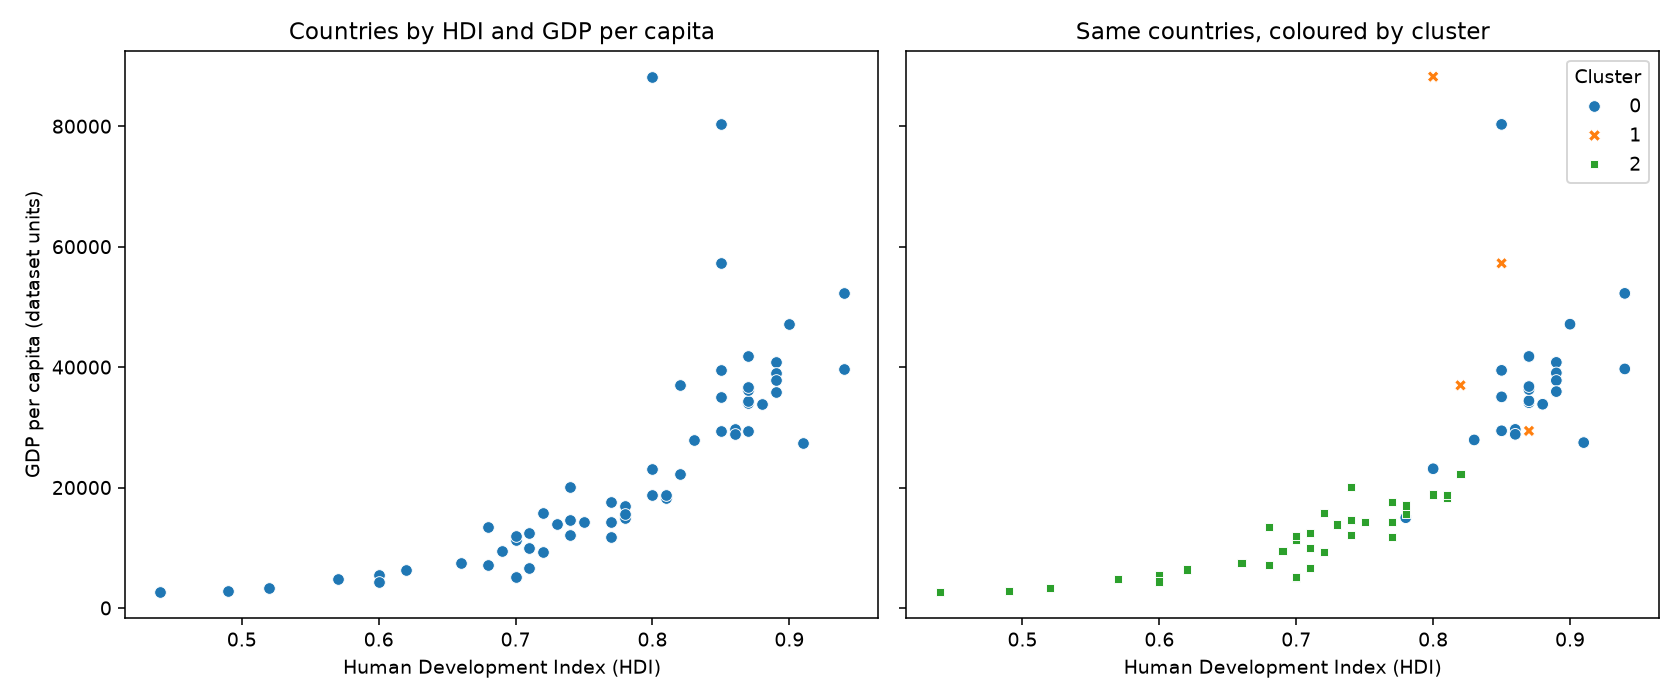

In [5]:
# 4.1 Compare the same two axes before and after colouring

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
sns.scatterplot(data=df, x="ИРЧП", y="ВВП д/н", ax=axes[0])
sns.scatterplot(
    data=df_clusters, x="ИРЧП", y="ВВП д/н",
    hue="Cluster", style="Cluster", ax=axes[1],
)

axes[0].set_title("Countries by HDI and GDP per capita")
axes[1].set_title("Same countries, coloured by cluster")
for ax in axes:
    ax.set_xlabel("Human Development Index (HDI)")
axes[0].set_ylabel("GDP per capita (dataset units)")
axes[1].set_ylabel("")
fig.tight_layout()
plt.show()

# Interpretation:
# Both panels show the same 62 rows. Colours and marker shapes in the right panel show the labels.

In [6]:
# 4.2 Inspect two countries with close coordinates in the chart

selected = df_clusters["Страны"].isin(["Чили", "Аргентина"])
df_clusters.loc[selected, ["Страны", "ИРЧП", "ВВП д/н", "Cluster"]]

# Interpretation:
# Chile and Argentina both have HDI 0.78 and similar GDP per capita in the file.
# They receive different labels because the assignment uses eight features.

,Страны,ИРЧП,ВВП д/н,Cluster
32,Чили,0.78,14982.0,0
33,Аргентина,0.78,15603.0,2


## **5. Compare Candidate Partitions**

For one observation let a be its mean distance to the other members of its group. Let b be its smallest mean distance to any other group. The silhouette is (b - a) / max(a, b). Values close to 1 indicate that the observation is closer to its own group. Values near zero indicate little separation, and negative values mean another group is closer on average. The average silhouette summarises these values across the observations.

Compare scores on the same features and scale. A model can have a higher score and still produce a group too small for the purpose of a briefing. [Silhouette score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html), [example of comparing parameters](https://github.com/artamonoff/ML-intro/blob/60ab7418e8d50ecead23b700636083bc5d7a05ea/clustering-performance.ipynb).

In [7]:
# 5.1 Calculate the average silhouette for the three-cluster model

score_three = silhouette_score(X_scaled, model.labels_)
print(f"Average silhouette for k=3: {score_three:.3f}")

# Interpretation:
# The score is about 0.273. It is an internal comparison of distances.

Average silhouette for k=3: 0.273


In [8]:
# 5.2 Compare two values of k, keeping all other settings fixed

rows = []
for k in [3, 4]:
    candidate = KMeans(n_clusters=k, init="random", n_init=10, random_state=0)
    candidate.fit(X_scaled)
    counts = pd.Series(candidate.labels_).value_counts().sort_index()
    score = silhouette_score(X_scaled, candidate.labels_)
    rows.append({
        "k": k,
        "Silhouette": round(score, 3),
        "Cluster sizes": counts.tolist(),
        "Smallest group": int(counts.min()),
    })

comparison = pd.DataFrame(rows)
comparison

# Interpretation:
# Four groups score 0.306, above 0.273 for three groups. The smallest group falls from four to two.

,k,Silhouette,Cluster sizes,Smallest group
0,3,0.273,"[24, 4, 34]",4
1,4,0.306,"[2, 23, 32, 5]",2


## **6. Describe the Groups in the Original Units**

The profile below combines the number of countries with the group medians. Describe the indicators and keep the sample size in view.

In [9]:
# 6.1 Summarise the three-cluster result

columns = ["ИРЧП", "Безработица (%)"]
medians = df_clusters.groupby("Cluster")[columns].median()
sizes = df_clusters["Cluster"].value_counts().sort_index().rename("Countries")
profiles = medians.join(sizes)[["Countries", *columns]]
profiles.round(3)

# Interpretation:
# The group labelled 0 has 24 countries. Its median HDI is 0.870 and median unemployment is 8.15%.

,Countries,ИРЧП,Безработица (%)
Cluster,,,
0,24,0.870,8.15
1,4,0.835,2.25
2,34,0.710,9.45


## **7. Optional Comparison with Ward’s Method**

Agglomerative clustering starts with individual observations and merges groups step by step. Ward’s method chooses the merge that increases the within-group sum of squares least. For this comparison, use the same features and ask for three groups again. [AgglomerativeClustering](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html), [lecture repository example](https://github.com/artamonoff/ML-intro/blob/60ab7418e8d50ecead23b700636083bc5d7a05ea/clustering-agglomerative.ipynb).

In [10]:
# 7.1 Use the same input and compare membership

from sklearn.cluster import AgglomerativeClustering

ward = AgglomerativeClustering(n_clusters=3, linkage="ward")
ward_labels = ward.fit_predict(X_scaled)

counts = pd.Series(ward_labels).value_counts().sort_index()
print("Ward group sizes:", counts.tolist())
pd.crosstab(model.labels_, ward_labels, rownames=["K-means"], colnames=["Ward"])

# Interpretation:
# Ward produces groups of 35, 5 and 22 in this run.
# The table compares membership. The same digit is not a shared group name.

Ward group sizes: [35, 5, 22]


Ward,0,1,2
K-means,,,
0,1,1,22
1,0,4,0
2,34,0,0


The [dendrogram example](https://github.com/artamonoff/ML-intro/blob/60ab7418e8d50ecead23b700636083bc5d7a05ea/clustering-agglomerative-dendrogram.ipynb) shows the sequence of merges. In a [separate PCA example](https://github.com/artamonoff/ML-intro/blob/60ab7418e8d50ecead23b700636083bc5d7a05ea/clustering-and-PCA.ipynb), principal components serve as the input to clustering. In the [k-means notebook from the lecture repository](https://github.com/artamonoff/ML-intro/blob/60ab7418e8d50ecead23b700636083bc5d7a05ea/clustering-k-means.ipynb), t-SNE supplies coordinates for a plot of already assigned labels.

## **8. Summary**

- Check the feature columns and their scales before fitting.
- Use the standardised input for both k-means and the silhouette score.
- Attach the labels to the original table for a scatter plot or group summary.
- Explain the chosen partition with the score, group size and profile. The result depends on the indicators and the method.